In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from scipy.optimize import minimize

In [ ]:
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

TICKERS = ["FFC.KA", "MEBL.KA", "PSO.KA", "DGKC.KA", "UBL.KA", "INDU.KA", "OGDC.KA", "KEL.KA", "GHNI.KA", "PAEL.KA", "FCCL.KA", "HCAR.KA", "ATRL.KA", "SEARL.KA"]
END   = datetime.today()
START = END - timedelta(days = 10*365)
TRADING_DAYS = 252
RISK_FREE = 0.12

In [ ]:
data = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)
prices = data["Close"].ffill().dropna()
prices.tail()

Ticker,ATRL.KA,DGKC.KA,FCCL.KA,FFC.KA,GHNI.KA,HCAR.KA,INDU.KA,KEL.KA,MEBL.KA,OGDC.KA,PAEL.KA,PSO.KA,SEARL.KA,UBL.KA
Date,,,,,,,,,,,,,,
2026-11-05,986.1200,203.1900,58.7100,562.5200,"1,210.8199",199.5000,"1,821.7000",6.1400,555.0200,310.4700,33.0700,362.8200,76.6600,422.0000
2026-11-06,982.1600,200.4100,58.0500,562.6200,"1,203.6801",201.6100,"1,822.3600",6.1100,550.2500,312.8900,33.4800,355.1000,77.1300,425.3400
2026-11-10,949.1200,213.5100,63.6100,574.8600,"1,249.5800",205.6100,"1,846.4600",6.2100,570.7800,317.0200,34.7500,361.3300,81.2600,445.3000
2026-11-11,959.2300,210.0800,62.0900,574.0400,"1,251.5400",208.0700,"1,837.9200",6.1600,563.9200,316.0900,35.4400,374.6800,81.0600,441.7200
2026-11-12,954.0100,206.3700,61.5400,570.1900,"1,287.1801",205.2200,"1,831.8199",6.2600,558.1800,313.3900,35.8000,368.2500,79.5300,437.2300


In [ ]:
print(START)

2016-11-15 17:28:07.024167


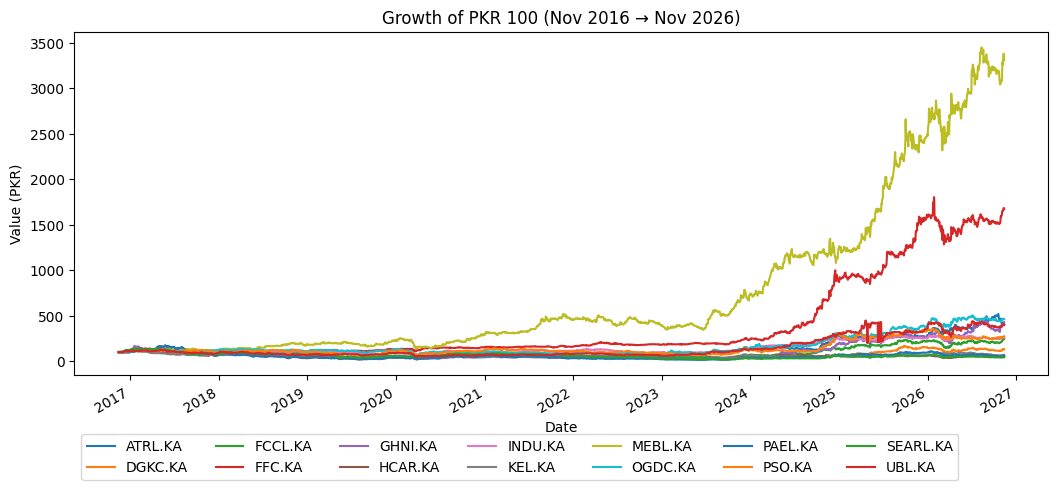

In [ ]:
import matplotlib.pyplot as plt

norm = prices / prices.iloc[0] * 100
ax = norm.plot(figsize=(11, 5), linewidth=1.5)
ax.set_title("Growth of PKR 100 (Nov 2016 → Nov 2026)")
ax.set_ylabel("Value (PKR)")
ax.legend(loc="upper left", ncol=7, bbox_to_anchor=(0, -0.15))
plt.tight_layout(); plt.show()

In [ ]:
log_returns = np.log(prices / prices.shift(1)).dropna()

mean_annual = log_returns.mean() * TRADING_DAYS
cov_annual  = log_returns.cov() * TRADING_DAYS
vol_annual  = np.sqrt(np.diag(cov_annual))

stock_metrics = pd.DataFrame({
    "Annual Return": mean_annual,
    "Annual Volatility": vol_annual,
    "Sharpe": (mean_annual - RISK_FREE) / vol_annual,
})
stock_metrics

,Annual Return,Annual Volatility,Sharpe
Ticker,,,
ATRL.KA,0.1347,0.4487,0.0328
DGKC.KA,0.0263,0.4062,-0.2308
FCCL.KA,0.0872,0.3809,-0.0862
FFC.KA,0.2744,0.2441,0.6325
GHNI.KA,0.1422,0.4950,0.0449
HCAR.KA,-0.0725,0.4304,-0.4473
INDU.KA,0.0925,0.2510,-0.1096
KEL.KA,-0.0366,0.4610,-0.3396
MEBL.KA,0.3409,0.2883,0.7661


In [ ]:
downside_returns = log_returns.clip(upper=0)
downside_deviation = np.sqrt((downside_returns ** 2).mean()) * np.sqrt(252)
annualized_return = log_returns.mean() * 252
sortino_ratio = annualized_return / downside_deviation.replace(0, np.nan)
wealth = np.exp(log_returns.cumsum())
initial_date = log_returns.index[0] - pd.Timedelta(days=1)
initial_wealth = pd.DataFrame(
    [np.ones(len(TICKERS))],
    columns=TICKERS,
    index=[initial_date])

wealth = pd.concat([initial_wealth, wealth]).sort_index()
running_peak = wealth.cummax()
drawdown = (wealth / running_peak) - 1
max_drawdown = drawdown.min()

In [ ]:
skewness = log_returns.skew()
kurtosis = log_returns.kurtosis()

In [ ]:
var_95 = -log_returns.quantile(0.05)
cvar_95 = -log_returns.apply(lambda x: x[x <= x.quantile(0.05)].mean())

In [ ]:
stock_metrics["Sortino Ratio"] = sortino_ratio
stock_metrics["Maximum Drawdown"] = max_drawdown
stock_metrics["Skewness"] = skewness
stock_metrics["Kurtosis"] = kurtosis
stock_metrics["VaR (95%)"] = var_95
stock_metrics["CVaR (95%)"] = cvar_95

display(stock_metrics)

,Annual Return,Annual Volatility,Sharpe,Sortino Ratio,Maximum Drawdown,Skewness,Kurtosis,VaR (95%),CVaR (95%)
Ticker,,,,,,,,,
ATRL.KA,0.1347,0.4487,0.0328,0.4408,-0.8515,0.1250,0.9202,0.0498,0.0610
DGKC.KA,0.0263,0.4062,-0.2308,0.0951,-0.8131,0.2313,1.3281,0.0433,0.0557
FCCL.KA,0.0872,0.3809,-0.0862,0.3477,-0.7040,0.4024,2.0196,0.0363,0.0508
FFC.KA,0.2744,0.2441,0.6325,1.7790,-0.3864,0.4409,8.0492,0.0197,0.0330
GHNI.KA,0.1422,0.4950,0.0449,0.4300,-0.8928,0.2246,0.6031,0.0510,0.0640
HCAR.KA,-0.0725,0.4304,-0.4473,-0.2479,-0.8898,0.3066,1.5593,0.0463,0.0591
INDU.KA,0.0925,0.2510,-0.1096,0.5400,-0.5692,0.0539,4.7438,0.0223,0.0376
KEL.KA,-0.0366,0.4610,-0.3396,-0.1247,-0.8529,0.9387,5.1416,0.0409,0.0587
MEBL.KA,0.3409,0.2883,0.7661,1.8705,-0.4619,0.3304,3.7202,0.0249,0.0383


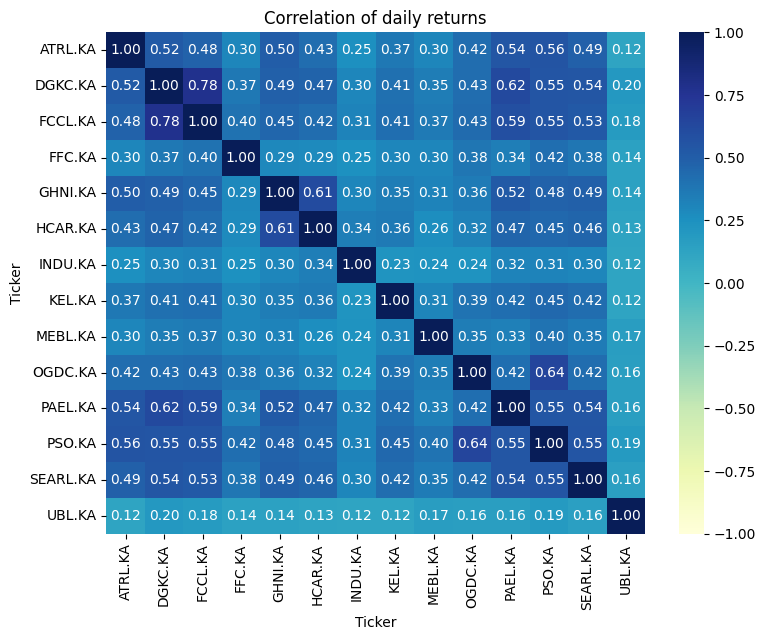

In [ ]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(log_returns.corr(), annot=True, fmt=".2f", cmap="YlGnBu", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of daily returns")
plt.tight_layout(); plt.show()

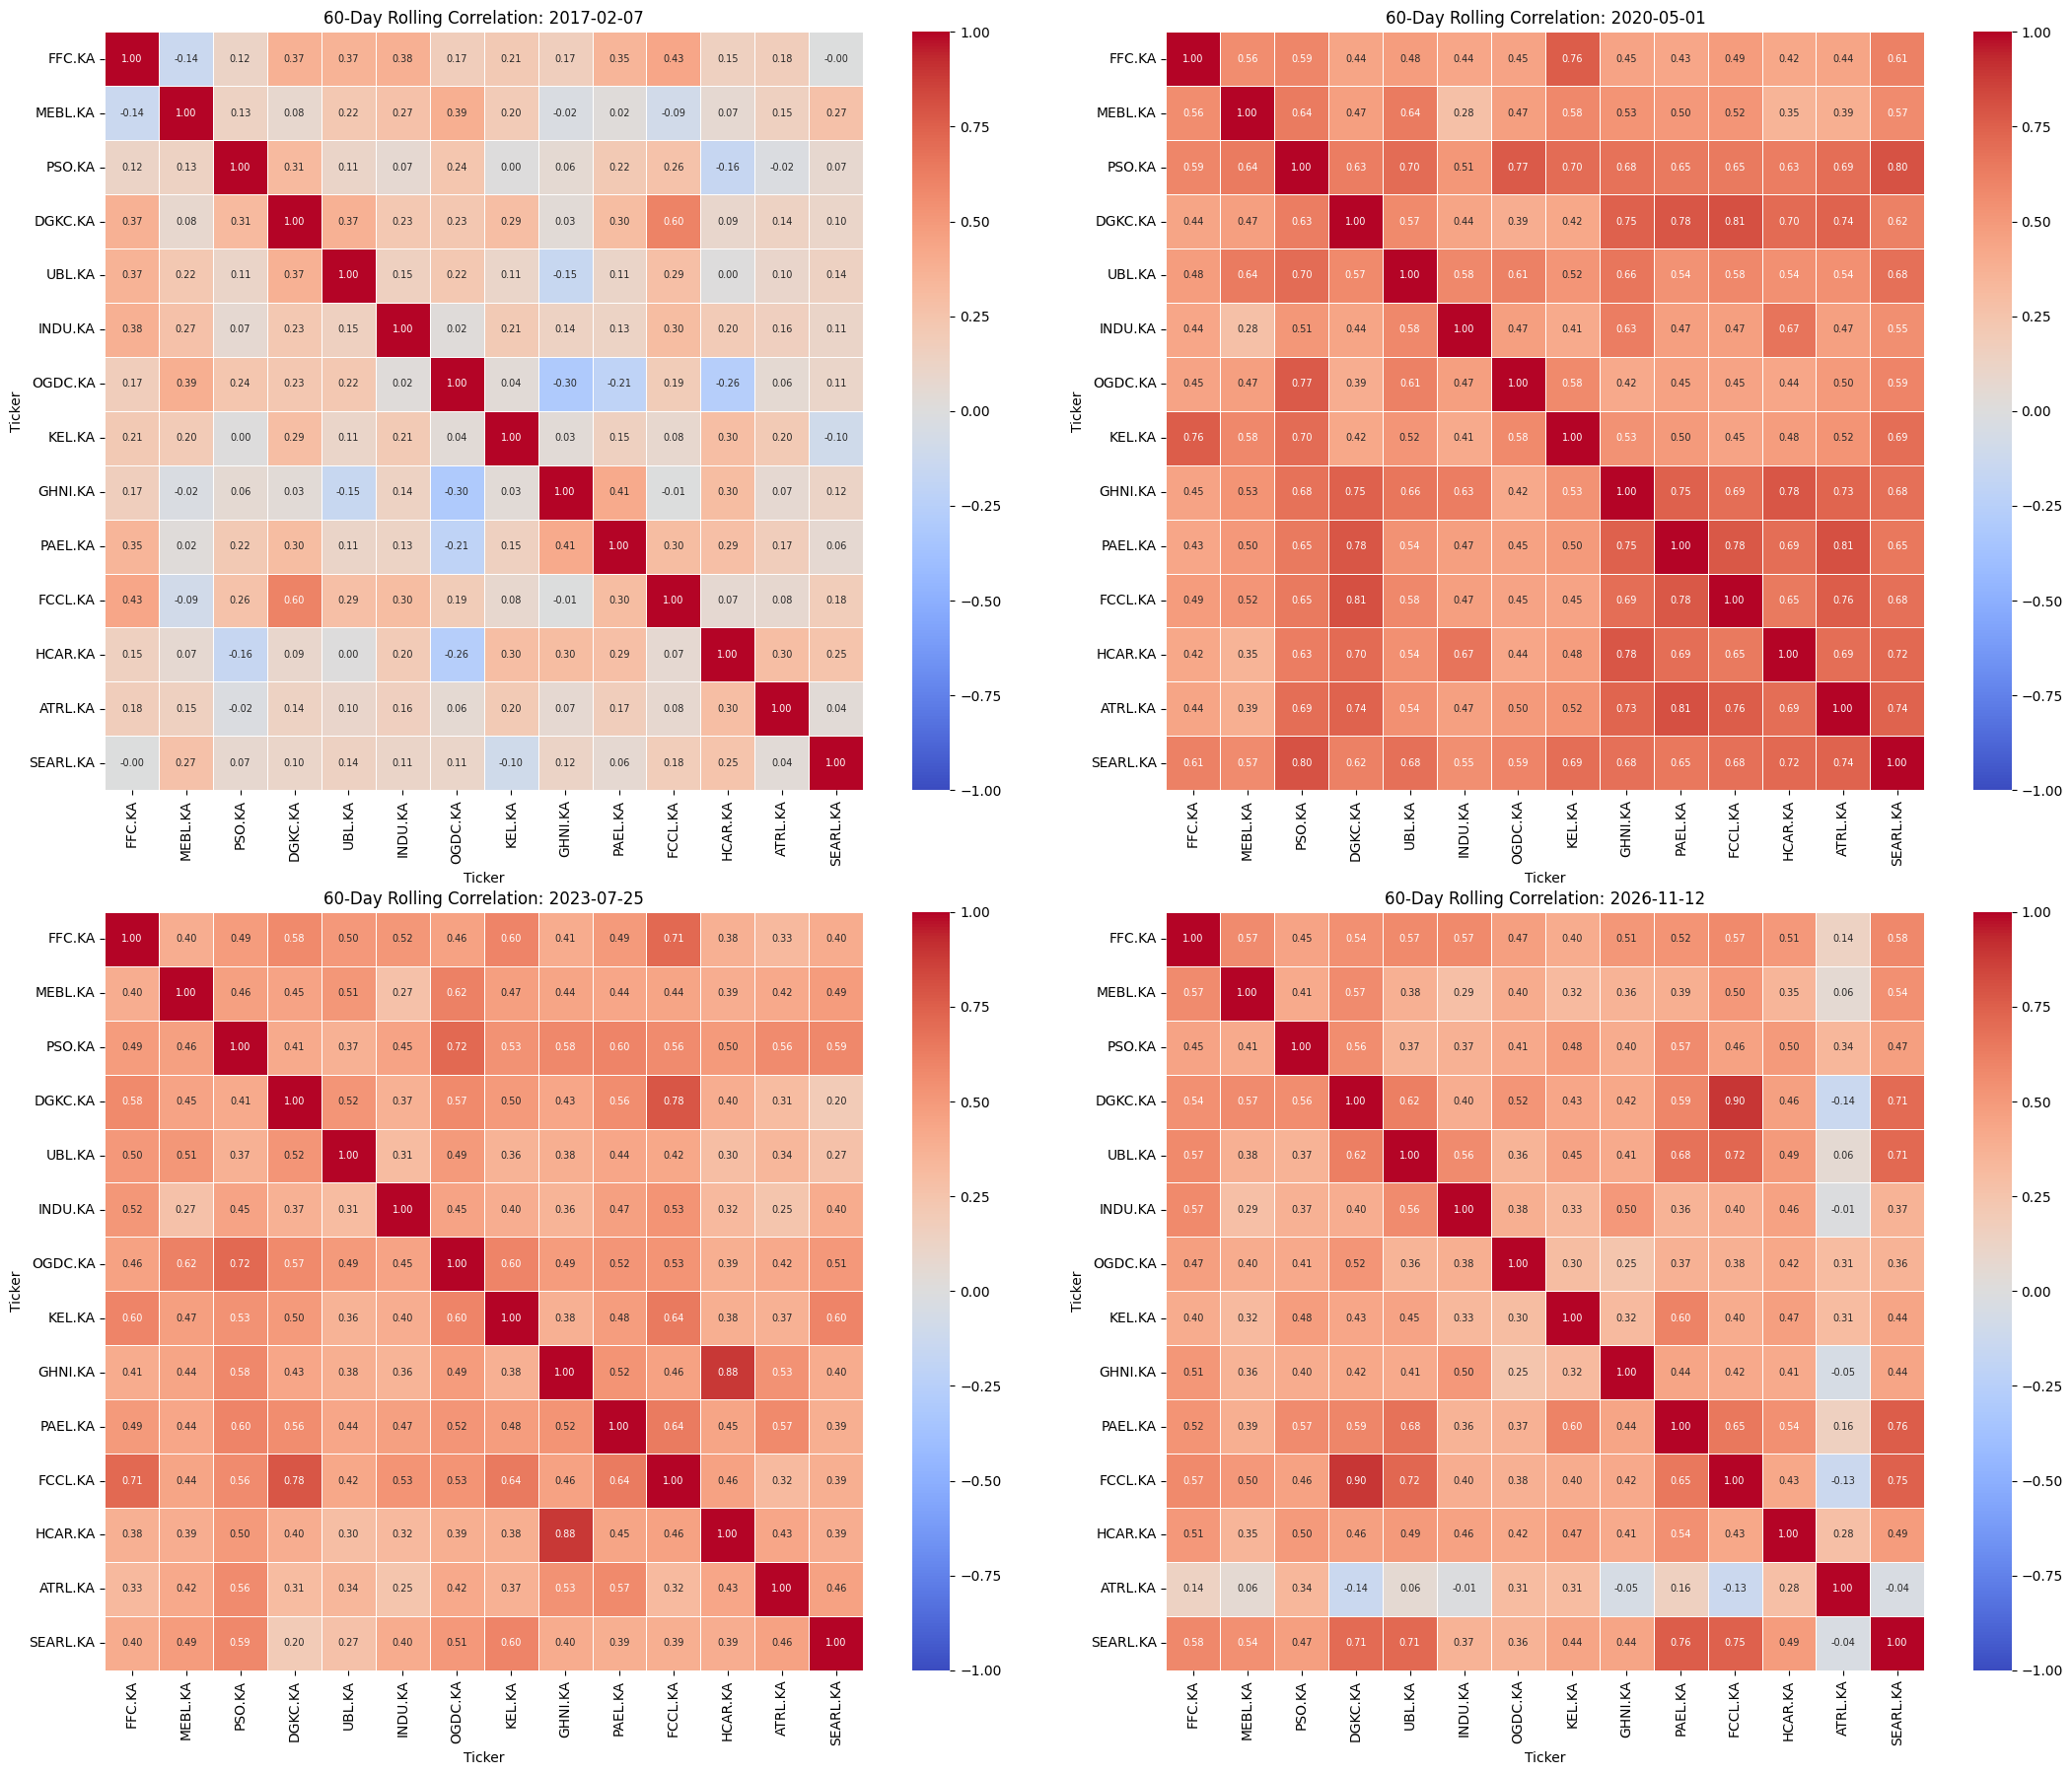

In [ ]:
rolling_corr = log_returns[TICKERS].rolling(window=60, min_periods=60).corr()
valid_dates = rolling_corr.index.get_level_values(0).unique()
valid_dates = [date for date in valid_dates
    if rolling_corr.loc[date].notna().values.any()]

snapshot_indices = np.linspace(
    0,
    len(valid_dates) - 1,
    min(4, len(valid_dates)),
    dtype=int)

snapshot_dates = [valid_dates[i] for i in snapshot_indices]

fig, axes = plt.subplots(2, 2, figsize=(22, 18))
axes = axes.flatten()

for i, date in enumerate(snapshot_dates):
    corr_matrix = rolling_corr.loc[date]
    corr_matrix = corr_matrix.dropna(axis=0, how="all").dropna(axis=1, how="all")

    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        ax=axes[i],
        annot_kws={"size": 7})

    axes[i].set_title(
        f"60-Day Rolling Correlation: {date.strftime('%Y-%m-%d')}",
        fontsize=12)

    axes[i].tick_params(axis="x", rotation=90)
    axes[i].tick_params(axis="y", rotation=0)

for j in range(len(snapshot_dates), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


In [ ]:
def portfolio_perf(w, mean=mean_annual, cov=cov_annual, rf=RISK_FREE):
    ret = w @ mean
    vol = np.sqrt(w @ cov @ w)
    return ret, vol, (ret - rf) / vol

np.random.seed(42)
N = 20_000
n = len(TICKERS)
results = np.zeros((3, N))
for i in range(N):
    w = np.random.random(n); w /= w.sum()
    results[:, i] = portfolio_perf(w)

mc = pd.DataFrame(results.T, columns=["return", "volatility", "sharpe"])
mc.describe().round(4)

,return,volatility,sharpe
count,"20,000.0000","20,000.0000","20,000.0000"
mean,0.0887,0.2606,-0.1185
std,0.0192,0.0117,0.0710
min,0.0121,0.2174,-0.3774
25%,0.0757,0.2525,-0.1669
50%,0.0887,0.2603,-0.1203
75%,0.1015,0.2684,-0.0727
max,0.1622,0.3049,0.1807


In [ ]:
def neg_sharpe(w):
  return -portfolio_perf(w)[2]
def port_vol(w):
  return portfolio_perf(w)[1]
def port_ret(w):
  return portfolio_perf(w)[0]

bounds = [(0, 0.20)] * n
initial_weights = np.repeat(1/n, n)
constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}

opt_max_sharpe = minimize(neg_sharpe, initial_weights, method="SLSQP", bounds=bounds, constraints=[constraints])
opt_min_var    = minimize(port_vol,   initial_weights, method="SLSQP", bounds=bounds, constraints=[constraints])

w_max_sharpe = opt_max_sharpe.x
w_min_var    = opt_min_var.x
w_equal      = initial_weights.copy()

def portfolio_summary(w, label):
    r, v, s = portfolio_perf(w)
    return {"Strategy": label, "Return": r, "Volatility": v, "Sharpe": s,
            **dict(zip(TICKERS, w.round(4)))}

portfolios = pd.DataFrame([
    portfolio_summary(w_equal,      "Equal-Weight"),
    portfolio_summary(w_min_var,    "Min Variance"),
    portfolio_summary(w_max_sharpe, "Max Sharpe"),
])
portfolios

,Strategy,Return,Volatility,Sharpe,FFC.KA,MEBL.KA,PSO.KA,DGKC.KA,UBL.KA,INDU.KA,OGDC.KA,KEL.KA,GHNI.KA,PAEL.KA,FCCL.KA,HCAR.KA,ATRL.KA,SEARL.KA
0,Equal-Weight,0.0887,0.2558,-0.1223,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714,0.0714
1,Min Variance,0.1769,0.1954,0.2914,0.0094,0.0000,0.0328,0.2000,0.0000,0.0543,0.2000,0.0209,0.2000,0.2000,0.0000,0.0133,0.0211,0.0482
2,Max Sharpe,0.1988,0.2004,0.3934,0.0747,0.0000,0.0000,0.2000,0.0539,0.0000,0.2000,0.0000,0.2000,0.2000,0.0000,0.0000,0.0000,0.0714


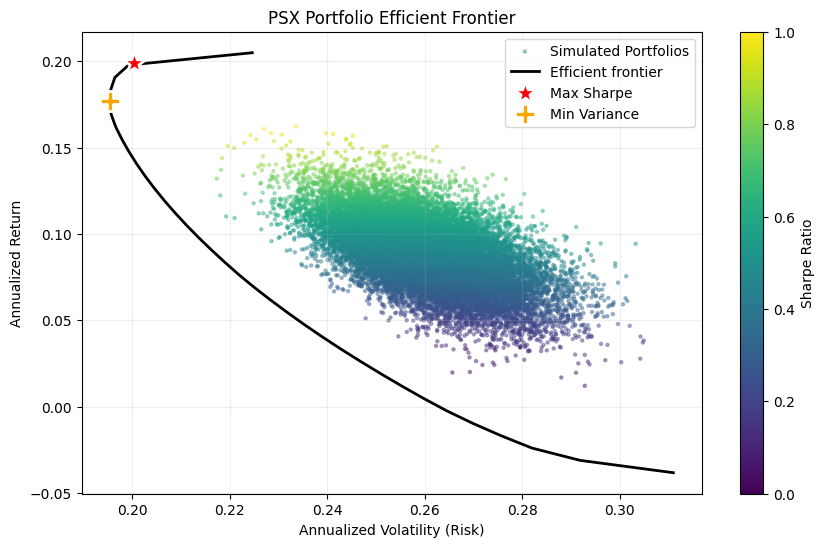

In [ ]:
target_returns = np.linspace(mean_annual.min(), mean_annual.max(), 60)
ef_vol = []
for tr in target_returns:
    cons = [constraints, {"type": "eq", "fun": lambda w, tr=tr: port_ret(w) - tr}]
    res = minimize(port_vol, initial_weights, method="SLSQP", bounds=bounds, constraints=cons)
    ef_vol.append(res.fun if res.success else np.nan)
ef_vol = np.array(ef_vol)

plt.figure(figsize=(10, 6))
plt.scatter(mc.volatility, mc["return"], c=mc.sharpe, cmap="viridis", s=5, alpha=0.4, label='Simulated Portfolios')
plt.plot(ef_vol, target_returns, "k-", lw=2, label="Efficient frontier")

mr, mv, _ = portfolio_perf(w_max_sharpe)
nr, nv, _ = portfolio_perf(w_min_var)
plt.scatter(mv, mr, color="red",   s=300, marker="*", label="Max Sharpe", zorder=5, ec="white", lw=2)
plt.scatter(nv, nr, color="orange",s=200, marker="P", label="Min Variance",  zorder=5, ec="white", lw=2)

plt.xlabel("Annualized Volatility (Risk)")
plt.ylabel("Annualized Return")
plt.title("PSX Portfolio Efficient Frontier")
plt.legend()
plt.colorbar(label="Sharpe Ratio")
plt.grid(alpha=0.2)

plt.show()

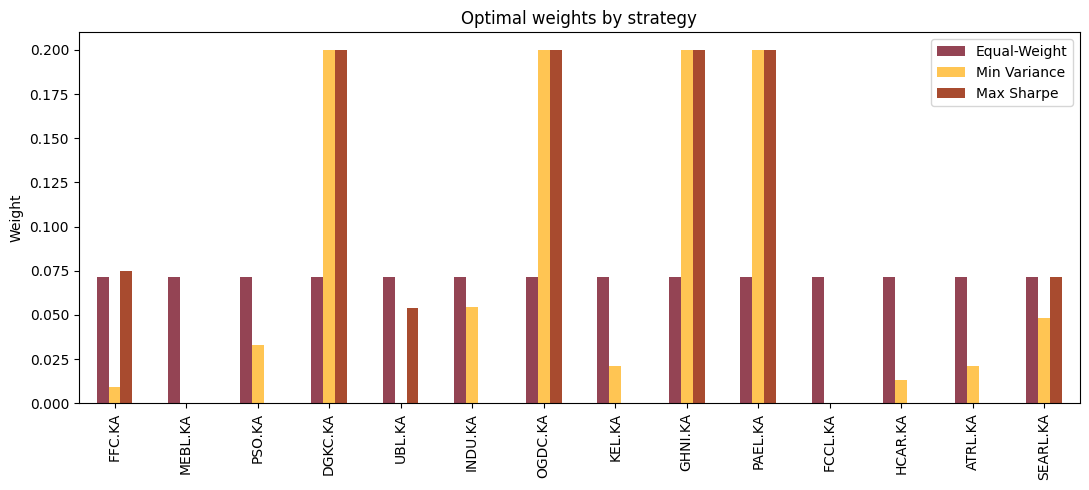

In [ ]:
alloc = pd.DataFrame({
    "Equal-Weight": w_equal,
    "Min Variance": w_min_var,
    "Max Sharpe":   w_max_sharpe,
}, index=TICKERS)
alloc.plot(kind="bar", figsize=(11, 5), color=["#944454", "#FFC553", "#A84B2F"])
plt.title("Optimal weights by strategy")
plt.ylabel("Weight")
plt.legend()
plt.tight_layout()
plt.show()

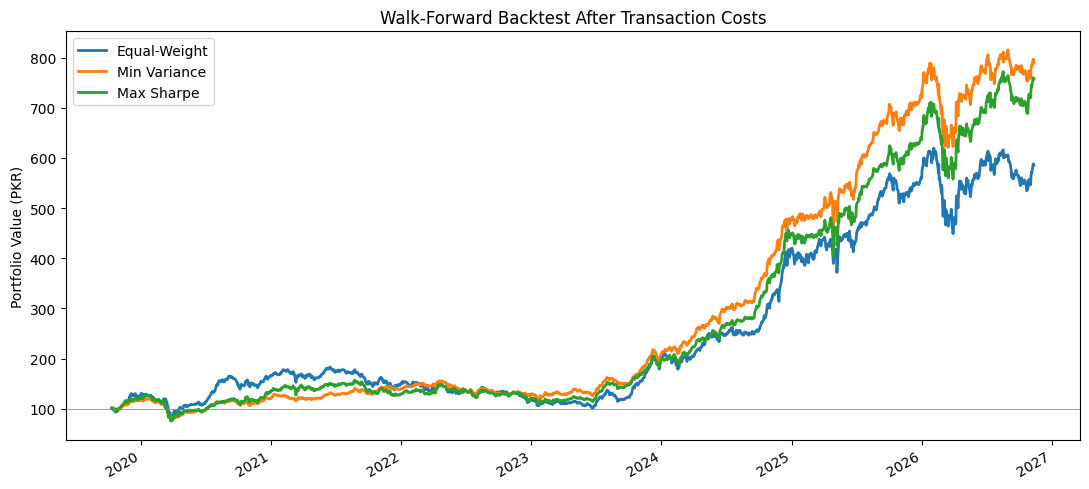

,Strategy,Average Quarterly Turnover
0,Equal-Weight,0.0522
1,Min Variance,0.0619
2,Max Sharpe,0.1476


In [ ]:
daily_returns = prices.pct_change().dropna()
COST_RATE = 0.001

results = {"Equal-Weight": [], "Min Variance": [], "Max Sharpe": []}
turnover_results = {"Equal-Weight": [], "Min Variance": [], "Max Sharpe": []}
previous_weights = {}
backtest_dates = []
for start in range(756, len(daily_returns), 63):
    train = daily_returns.iloc[start-756:start]
    test = daily_returns.iloc[start:start+63]
    mu = train.mean() * TRADING_DAYS
    cov = train.cov() * TRADING_DAYS
    n = len(TICKERS)

    def portfolio_vol(w):
        return np.sqrt(w @ cov.values @ w)

    def negative_sharpe(w):
        vol = portfolio_vol(w)
        return -((w @ mu.values - RISK_FREE) / vol) if vol > 0 else 1e10

    constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
    bounds = [(0, 0.20)] * n
    initial = np.ones(n) / n
    min_result = minimize(portfolio_vol, initial, method="SLSQP",
                          bounds=bounds, constraints=constraints)
    sharpe_result = minimize(negative_sharpe, initial, method="SLSQP",
                             bounds=bounds, constraints=constraints)

    portfolios = {
        "Equal-Weight": initial,
        "Min Variance": min_result.x if min_result.success else initial,
        "Max Sharpe": sharpe_result.x if sharpe_result.success else initial}
    for name, target in portfolios.items():
        turnover = (0.5 * np.abs(target - previous_weights[name]).sum()
                    if name in previous_weights else 0)
        turnover_results[name].append(turnover)
        weights = target.copy()

        for i, (_, returns) in enumerate(test.iterrows()):
            gross_return = weights @ returns.values
            net_return = ((1 + gross_return) * (1 - COST_RATE * turnover) - 1
                if i == 0 else gross_return)
            results[name].append(net_return)
            weights = weights * (1 + returns.values) / (1 + gross_return)
        previous_weights[name] = weights.copy()
    backtest_dates.extend(test.index)

cum = pd.DataFrame({
    name: (1 + pd.Series(values, index=backtest_dates)).cumprod() * 100
    for name, values in results.items()})

cum.plot(figsize=(11, 5), lw=2)
plt.axhline(100, color="gray", lw=0.5)
plt.title("Walk-Forward Backtest After Transaction Costs")
plt.ylabel("Portfolio Value (PKR)")
plt.tight_layout()
plt.show()

turnover_summary = pd.DataFrame({"Strategy": list(turnover_results.keys()), "Average Quarterly Turnover": [np.mean(v) for v in turnover_results.values()]})
display(turnover_summary.round(4))

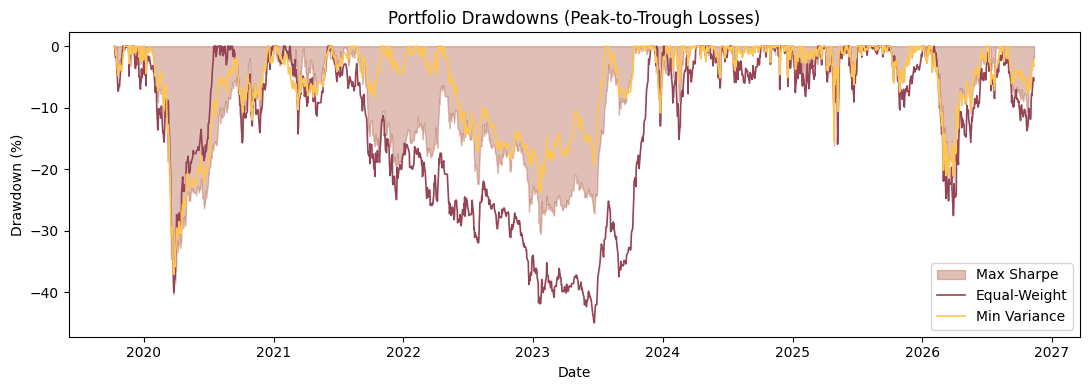

In [ ]:
def drawdown(s):
    wealth = pd.concat([pd.Series([100], index=[s.index[0] - pd.Timedelta(days=1)]), s])
    return (wealth - wealth.cummax()) / wealth.cummax()
dd = pd.DataFrame({c: drawdown(cum[c]).iloc[1:] for c in cum.columns})

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(dd.index, dd["Max Sharpe"] * 100, 0, color="#A84B2F", alpha=0.35, label="Max Sharpe")
ax.plot(dd.index, dd["Equal-Weight"] * 100, color="#944454", lw=1.2, label="Equal-Weight")
ax.plot(dd.index, dd["Min Variance"] * 100, color="#FFC553", lw=1.2, label="Min Variance")
ax.set_title("Portfolio Drawdowns (Peak-to-Trough Losses)")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
def summary(r, label):
    # Re-align with the datetime index used in backtesting
    r = pd.Series(r, index=backtest_dates)
    wealth = (1 + r).cumprod() * 100
    ann_ret = (wealth.iloc[-1] / 100) ** (TRADING_DAYS / len(r)) - 1
    ann_vol = r.std() * np.sqrt(TRADING_DAYS)
    return {
        "Strategy": label,
        "Total Return": (wealth.iloc[-1] / 100) - 1,
        "Annualized Return": ann_ret,
        "Annualized Volatility": ann_vol,
        "Sharpe": (ann_ret - RISK_FREE) / ann_vol,
        "Max Drawdown": drawdown(wealth).min(),
    }

performance_summary = pd.DataFrame([
    summary(results["Equal-Weight"], "Equal-Weight"),
    summary(results["Min Variance"], "Min Variance"),
    summary(results["Max Sharpe"], "Max Sharpe"),
])

display(performance_summary.round(4))

,Strategy,Total Return,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
0,Equal-Weight,4.8519,0.2754,0.2621,0.5932,-0.4494
1,Min Variance,6.8888,0.3290,0.2072,1.0087,-0.3705
2,Max Sharpe,6.5725,0.3215,0.2345,0.8592,-0.4032
